# NASA Airfoil Self-Noise — Starter Notebook
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [UCI Machine Learning Repository — Airfoil Self-Noise](https://archive.ics.uci.edu/dataset/291/airfoil+self+noise)

NASA tested airfoil sections in an anechoic wind tunnel. Each row is one measurement: the test conditions and the sound pressure level recorded.

| Column | Description | Units |
|---|---|---|
| `frequency_hz` | Frequency | Hz |
| `angle_deg` | Angle of attack | degrees |
| `chord_m` | Chord length | m |
| `velocity_ms` | Free-stream velocity | m/s |
| `displacement_m` | Suction-side displacement thickness | m |
| `sound_db` | Scaled sound pressure level | dB |

This notebook only loads the data and makes a few basic plots. The analysis is up to you.

> The first run downloads the data (internet required) and saves it in a local `data/` folder.

## 1. Load the data

In [1]:
from pathlib import Path
import io, zipfile
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
ZIP_PATH = DATA / 'airfoil_uci291.zip'
URL = 'https://archive.ics.uci.edu/static/public/291/airfoil+self+noise.zip'

if not ZIP_PATH.is_file():
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    ZIP_PATH.write_bytes(r.content)

cols = ['frequency_hz', 'angle_deg', 'chord_m', 'velocity_ms', 'displacement_m', 'sound_db']
with zipfile.ZipFile(ZIP_PATH) as z:
    df = pd.read_csv(io.BytesIO(z.read('airfoil_self_noise.dat')), sep=r'\s+', header=None, names=cols)

print(df.shape)
df.head()

(1503, 6)


,frequency_hz,angle_deg,chord_m,velocity_ms,displacement_m,sound_db
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
frequency_hz,1503.0,2886.380572,3152.573137,200.000000,800.000000,1600.000000,4000.000000,20000.000000
angle_deg,1503.0,6.782302,5.918128,0.000000,2.000000,5.400000,9.900000,22.200000
chord_m,1503.0,0.136548,0.093541,0.025400,0.050800,0.101600,0.228600,0.304800
velocity_ms,1503.0,50.860745,15.572784,31.700000,39.600000,39.600000,71.300000,71.300000
displacement_m,1503.0,0.011140,0.013150,0.000401,0.002535,0.004957,0.015576,0.058411
sound_db,1503.0,124.835943,6.898657,103.380000,120.191000,125.721000,129.995500,140.987000


## 2. A first look

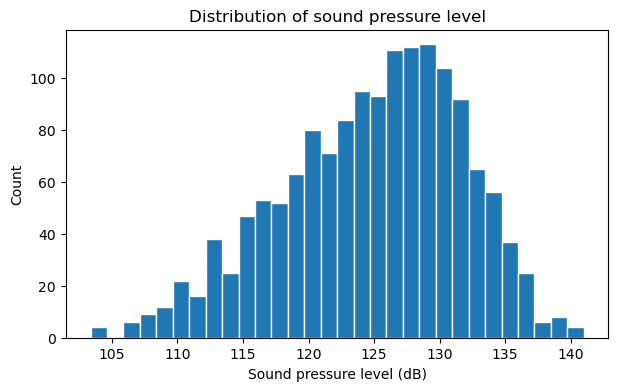

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['sound_db'], bins=30, edgecolor='white')
ax.set(xlabel='Sound pressure level (dB)', ylabel='Count', title='Distribution of sound pressure level')
plt.show()

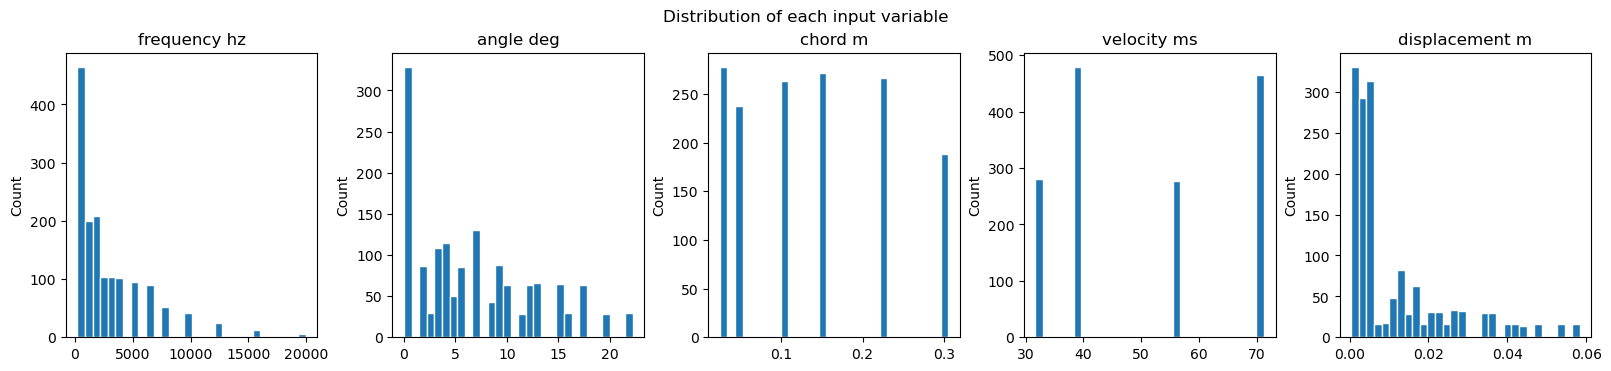

In [4]:
inputs = df.columns.drop('sound_db')
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6), constrained_layout=True)
for ax, col in zip(axs, inputs):
    ax.hist(df[col], bins=30, edgecolor='white')
    ax.set(title=col.replace('_', ' '), ylabel='Count')
fig.suptitle('Distribution of each input variable')
plt.show()

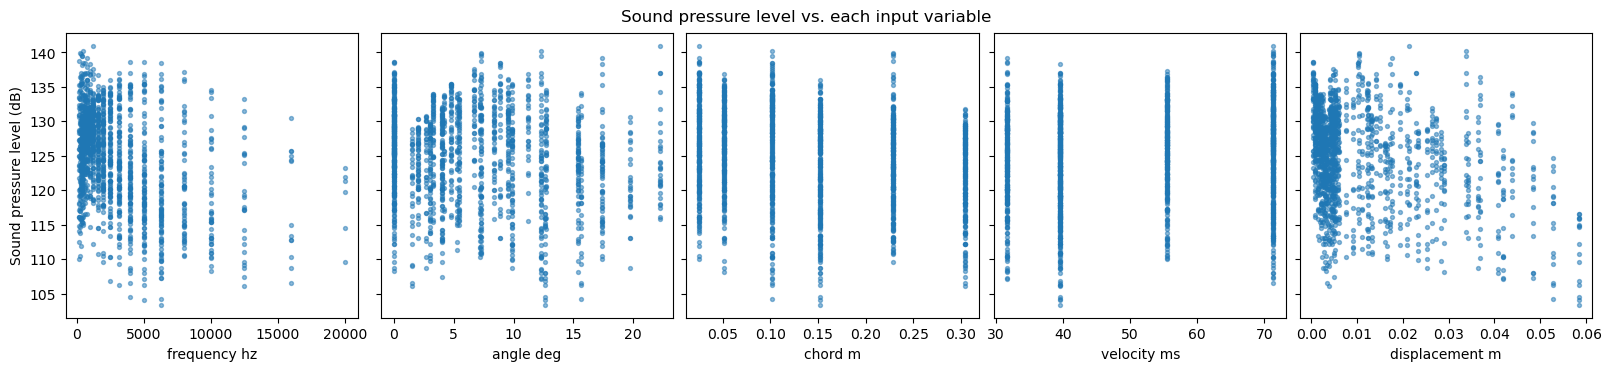

In [5]:
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True, constrained_layout=True)
for ax, col in zip(axs, inputs):
    ax.scatter(df[col], df['sound_db'], s=8, alpha=0.5)
    ax.set(xlabel=col.replace('_', ' '))
axs[0].set_ylabel('Sound pressure level (dB)')
fig.suptitle('Sound pressure level vs. each input variable')
plt.show()

## 3. Your exploration
Add your own analysis below.